In [1]:
import pandas as pd

df = pd.read_csv('health_study_dataset.csv')

print(df.head())

   id  age sex  height  weight  systolic_bp  cholesterol smoker  disease
0   1   57   F   168.9    65.8        141.8         4.58     No        0
1   2   47   M   180.4    95.9        144.8         5.18    Yes        0
2   3   59   F   169.9    82.2        151.7         6.16     No        0
3   4   72   M   157.7    93.1        151.0         6.63     No        0
4   5   46   M   192.6   104.1        144.1         5.21     No        0


| Variabel | Medelvärde (Mean) | Median | Minsta värde (Min) | Högsta värde (Max) |
| :--- | :--- | :--- | :--- | :--- |
| **Ålder (`age`)** | 49.43 år | 50.00 år | 18.0 år | 90.00 år |
| **Vikt (`weight`)** | 73.41 kg | 73.20 kg | 33.7 kg | 114.40 kg |
| **Längd (`height`)** | 171.85 cm | 171.35 cm | 144.4 cm | 200.40 cm |
| **Blodtryck (`systolic_bp`)** | 149.18 mmHg | 149.40 mmHg | 106.8 mmHg | 185.90 mmHg |
| **Kolesterol (`cholesterol`)** | 4.93 mmol/L | 4.97 mmol/L | 2.5 mmol/L | 7.88 mmol/L |

BESKRIVANDE STATISTIK
                   mean  median    min     max
age           49.426250   50.00   18.0   90.00
weight        73.413000   73.20   33.7  114.40
height       171.849250  171.35  144.4  200.40
systolic_bp  149.178625  149.40  106.8  185.90
cholesterol    4.929150    4.97    2.5    7.88


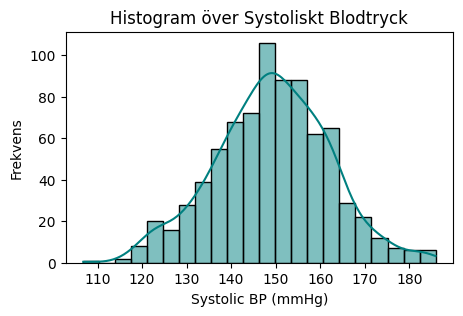

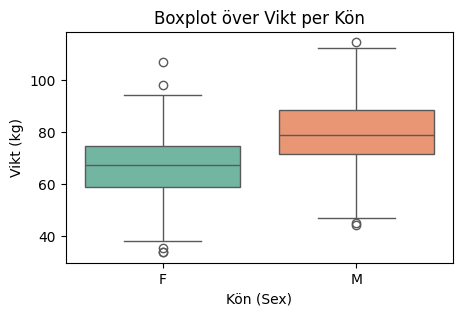

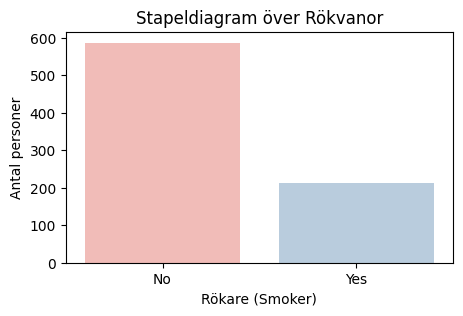

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('health_study_dataset.csv')


cols = ['age', 'weight', 'height', 'systolic_bp', 'cholesterol']
stats = df[cols].agg(['mean', 'median', 'min', 'max']).T
print("BESKRIVANDE STATISTIK")
print(stats)


plt.figure(figsize=(5, 3))
sns.histplot(df['systolic_bp'], kde=True, color='teal')
plt.title('Histogram över Systoliskt Blodtryck')
plt.xlabel('Systolic BP (mmHg)')
plt.ylabel('Frekvens')
plt.show()


plt.figure(figsize=(5, 3))
sns.boxplot(x='sex', y='weight', data=df, palette='Set2', legend=False)
plt.title('Boxplot över Vikt per Kön')
plt.xlabel('Kön (Sex)')
plt.ylabel('Vikt (kg)')
plt.show()


plt.figure(figsize=(5, 3))
sns.countplot(x='smoker', data=df, palette='Pastel1', legend=False)
plt.title('Stapeldiagram över Rökvanor')
plt.xlabel('Rökare (Smoker)')
plt.ylabel('Antal personer')
plt.show()

In [3]:
import pandas as pd
import numpy as np


df = pd.read_csv('health_study_dataset.csv')


true_disease_count = df['disease'].sum()
total_people = len(df)
true_proportion = true_disease_count / total_people
print(f"Antal personer i datasetet: {total_people}")
print(f"Antal med sjukdomen: {true_disease_count}")
print(f"Verklig andandel: {true_proportion:.4f} ({true_proportion * 100:.2f}%)")


np.random.seed(42)  
simulated_people = 1000
simulated_disease = np.random.binomial(n=1, p=true_proportion, size=simulated_people)
simulated_disease_count = simulated_disease.sum()
simulated_proportion = simulated_disease_count / simulated_people
print(f"\n SIMULERING (1000 st)")
print(f"Simulerat antal med sjukdom: {simulated_disease_count}")
print(f"Simulerad andandel: {simulated_proportion:.4f} ({simulated_proportion * 100:.2f}%)")


diff = abs(simulated_proportion - true_proportion)
print(f"\nSkillnad mellan simulering och verklighet: {diff:.4f}")

Antal personer i datasetet: 800
Antal med sjukdomen: 47
Verklig andandel: 0.0587 (5.88%)

 SIMULERING (1000 st)
Simulerat antal med sjukdom: 56
Simulerad andandel: 0.0560 (5.60%)

Skillnad mellan simulering och verklighet: 0.0027


In [4]:
import pandas as pd
import numpy as np
import scipy.stats as stats


df = pd.read_csv('health_study_dataset.csv')
bp = df['systolic_bp']


mean_bp = bp.mean()
std_error = bp.sem()  
n = len(bp)

# 95% konfidensintervall
ci_normal = stats.t.interval(0.95, df=n-1, loc=mean_bp, scale=std_error)

print(f"Medelvärde: {mean_bp:.2f} mmHg")
print(f"95% Konfidensintervall (Normalapproximation): ({ci_normal[0]:.2f}, {ci_normal[1]:.2f})")

# Konfidensintervall med Bootstrap
np.random.seed(42)
n_bootstraps = 10000
bootstrap_means = np.empty(n_bootstraps)

for i in range(n_bootstraps):
    sample = np.random.choice(bp, size=n, replace=True)
    bootstrap_means[i] = sample.mean()

ci_bootstrap = np.percentile(bootstrap_means, [2.5, 97.5])
print(f"95% Konfidensintervall (Bootstrap): ({ci_bootstrap[0]:.2f}, {ci_bootstrap[1]:.2f})")

Medelvärde: 149.18 mmHg
95% Konfidensintervall (Normalapproximation): (148.29, 150.07)
95% Konfidensintervall (Bootstrap): (148.30, 150.07)


In [5]:
import pandas as pd
import scipy.stats as stats


df = pd.read_csv('health_study_dataset.csv')


smokers = df[df['smoker'] == 'Yes']['systolic_bp']
non_smokers = df[df['smoker'] == 'No']['systolic_bp']


print(f"Medelblodtryck rökare: {smokers.mean():.2f} mmHg")
print(f"Medelblodtryck icke-rökare: {non_smokers.mean():.2f} mmHg")


t_stat, p_val = stats.ttest_ind(smokers, non_smokers, equal_var=False)

print(f"\nT-statistik: {t_stat:.4f}")
print(f"P-värde (tvåsidigt): {p_val:.4f}")

Medelblodtryck rökare: 149.52 mmHg
Medelblodtryck icke-rökare: 149.05 mmHg

T-statistik: 0.4503
P-värde (tvåsidigt): 0.6527


Resultatförklaring:
Det jämförde medelblodtrycket mellan rökare och icke rökare. Rökarna hade i genomsnitt 149.52 mmHg och icke rökare 149.05 mmHg. Skillnaden är väldigt liten. Eftersom p-värde är högt så det är ganska (0.65), beror skillnaden troligtvis bara på slumpen. Det kan därför inte säga att rökare har högre blodtryck än icke rökare baserat på den här datan.